# Part 1 - Crypto Market Regime Analysis

### 1. Objective

The objective of this project is to analyze the behavior of cryptocurrency markets using unsupervised learning techniques. In particular, we aim to identify distinct **market regimes** , such as periods of growth, decline, and high uncertainty, by applying clustering methods to historical Bitcoin data.

To achieve this, we first prepare and transform raw financial time series data into meaningful features, including returns, volatility, and changes in trading volume. These features are designed to capture different aspects of market dynamics.

We then apply clustering algorithms with the objective of grouping similar time periods together, allowing us to uncover hidden structure in the data without relying on predefined labels. The resulting clusters are interpreted as different market regimes, providing insight into how market conditions evolve over time.

This analysis serves as a foundation for further predictive modeling in Part 2, where we will attempt to model and predict market behavior using supervised learning methods.

In [1]:
!pip install yfinance --quiet

### 2. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import yfinance as yf

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

### 3. Load Data

In [ ]:
btc = yf.download("BTC-USD", start="2019-01-01")
btc.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2019-01-01,3843.520020,3850.913818,3707.231201,3746.713379,4324200990
2019-01-02,3943.409424,3947.981201,3817.409424,3849.216309,5244856836
2019-01-03,3836.741211,3935.685059,3826.222900,3931.048584,4530215219
2019-01-04,3857.717529,3865.934570,3783.853760,3832.040039,4847965467
2019-01-05,3845.194580,3904.903076,3836.900146,3851.973877,5137609824


In [ ]:
btc.columns = btc.columns.droplevel(1)
btc.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2019-01-01,3843.520020,3850.913818,3707.231201,3746.713379,4324200990
2019-01-02,3943.409424,3947.981201,3817.409424,3849.216309,5244856836
2019-01-03,3836.741211,3935.685059,3826.222900,3931.048584,4530215219
2019-01-04,3857.717529,3865.934570,3783.853760,3832.040039,4847965467
2019-01-05,3845.194580,3904.903076,3836.900146,3851.973877,5137609824


The dataset contains daily Bitcoin market data, where each row represents one trading day. The key variables include the opening price, closing price, highest and lowest prices during the day, and trading volume.

The closing price is particularly important, as it will be used to compute returns and other derived features. Trading volume provides information about market activity and will help capture periods of increased market participation.

At this stage, the data is still in raw form and will need to be transformed into meaningful features, such as returns and volatility, before applying clustering methods.

### 4. Feature Engineering

In [ ]:
# creating the returns variable

btc['return'] = btc['Close'].pct_change()
btc[['Close', 'return']].head()

Price,Close,return
Date,,
2019-01-01,3843.520020,NaN
2019-01-02,3943.409424,0.025989
2019-01-03,3836.741211,-0.027050
2019-01-04,3857.717529,0.005467
2019-01-05,3845.194580,-0.003246


### Interpretation of Returns

The computed returns represent the daily percentage change in Bitcoin's closing price.

Positive values indicate price increases (bullish days), while negative values indicate price decreases (bearish days). The first observation is missing (NaN) because there is no previous day to compute the return.

This transformation is essential, as returns provide a normalized and stationary representation of market movements, making them suitable for statistical modeling and clustering.

In [ ]:
# creating the volatility variable
btc['volatility'] = btc['return'].rolling(window=10).std()
btc[['return', 'volatility']].head(15)

Price,return,volatility
Date,,
2019-01-01,NaN,NaN
2019-01-02,0.025989,NaN
2019-01-03,-0.027050,NaN
2019-01-04,0.005467,NaN
2019-01-05,-0.003246,NaN
2019-01-06,0.060189,NaN
2019-01-07,-0.012605,NaN
2019-01-08,0.001391,NaN
2019-01-09,0.001104,NaN


### Interpretation of Volatility

Volatility is computed as the rolling standard deviation of returns over a 10-day window. It measures how much returns fluctuate over time.

Higher volatility indicates larger and more irregular price movements, reflecting increased market uncertainty, while lower volatility corresponds to more stable market conditions.

In [ ]:
# creating volume
btc['vol_change'] = btc['Volume'].pct_change()
btc[['return', 'volatility', 'vol_change']].head(15)

Price,return,volatility,vol_change
Date,,,
2019-01-01,NaN,NaN,NaN
2019-01-02,0.025989,NaN,0.212908
2019-01-03,-0.027050,NaN,-0.136256
2019-01-04,0.005467,NaN,0.070140
2019-01-05,-0.003246,NaN,0.059746
2019-01-06,0.060189,NaN,0.089422
2019-01-07,-0.012605,NaN,-0.065821
2019-01-08,0.001391,NaN,0.014912
2019-01-09,0.001104,NaN,-0.035934


### Interpretation of Volume Change

The variable `vol_change` measures the daily percentage change in trading volume. Positive values indicate an increase in market activity relative to the previous day, while negative values indicate a decrease.

This feature is useful because sudden changes in trading activity often accompany important shifts in market conditions and may help distinguish between different market regimes.

### 5. Data Cleaning

In [ ]:
btc[['return', 'volatility', 'vol_change']].isna().sum()

Price
return         1
volatility    10
vol_change     1
dtype: int64

In [ ]:
btc = btc.dropna()
btc[['return', 'volatility', 'vol_change']].isna().sum()

Price
return        0
volatility    0
vol_change    0
dtype: int64

### Data Cleaning

After constructing the features (returns, volatility, and volume change), the dataset contains missing values at the beginning of the time series.

These arise because returns require a previous observation, and volatility requires a rolling window of past data.

We handle this by removing all rows with missing values, ensuring that the dataset used for clustering is complete and consistent.

### 6. Feature Selection for Clustering

In [ ]:
features = btc[['return', 'volatility', 'vol_change']]

### Feature Selection

We select the variables return, volatility, and volume change as inputs for the clustering algorithm.

These features capture key aspects of market behavior:
- returns represent price direction
- volatility reflects market uncertainty
- volume change measures trading activity

### 7. Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

### Feature Scaling

Before applying clustering, we standardize the features using StandardScaler.

This ensures that all variables contribute equally to the clustering process, preventing features with larger magnitudes from dominating the distance calculations.

### 8. Choosing Number of Clusters (Elbow Method)

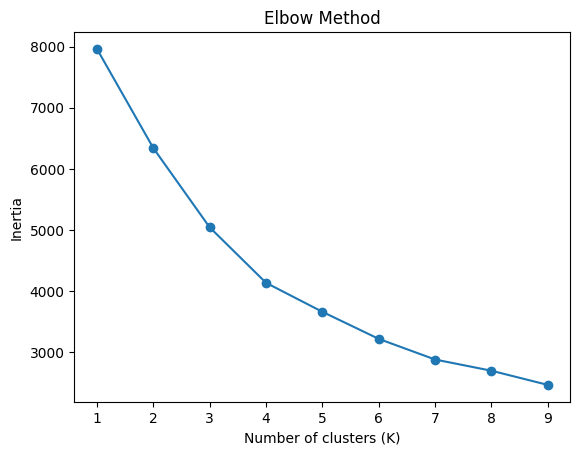

In [ ]:
inertia = []

for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 10), inertia, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

### Elbow Method Interpretation

To determine the appropriate number of clusters, we use the elbow method. This involves fitting the K-means algorithm for different values of K and measuring the corresponding inertia.

Inertia represents the total distance between each data point and the center of its assigned cluster. Lower inertia indicates that the data points are closer to their cluster centers, meaning the clusters are more compact and well-defined.

As the number of clusters increases, inertia naturally decreases because the model can fit the data more closely. However, after a certain point, the improvement becomes much smaller. This creates a visible “elbow” in the plot.

In our case, the curve shows a sharp decrease in inertia up to around K = 3 or 4, after which the decrease becomes more gradual. This suggests that adding more clusters beyond this point does not significantly improve the clustering.

Therefore, we choose K = 3 as a reasonable number of clusters, as it captures the main structure of the data while keeping the model simple and interpretable.

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
btc['cluster'] = kmeans.fit_predict(X_scaled)

btc[['return', 'volatility', 'vol_change', 'cluster']].head(10)

Price,return,volatility,vol_change,cluster
Date,,,,
2019-01-11,0.002294,0.037883,-0.194269,1
2019-01-12,-0.007069,0.036440,-0.137314,1
2019-01-13,-0.029593,0.036606,-0.020273,2
2019-01-14,0.043091,0.039826,0.207225,0
2019-01-15,-0.020339,0.040190,-0.020206,2
2019-01-16,0.006702,0.033566,-0.025778,1
2019-01-17,0.006445,0.033961,0.012969,1
2019-01-18,-0.005634,0.033807,-0.084448,1
2019-01-19,0.019336,0.034895,0.190433,0


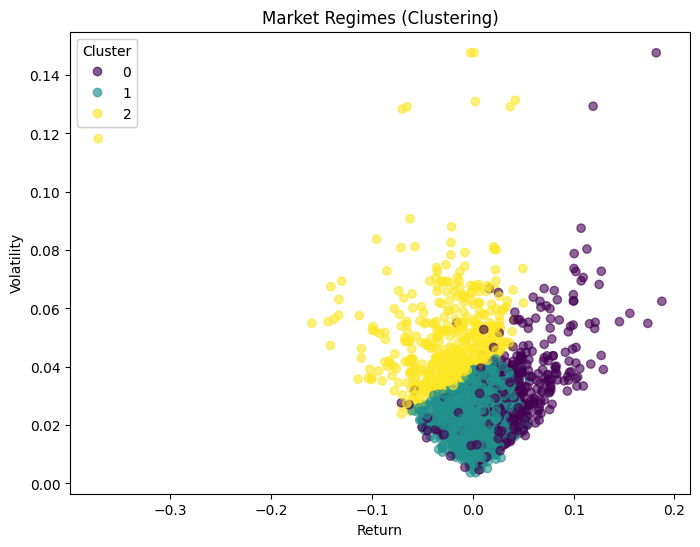

In [ ]:
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    btc['return'],
    btc['volatility'],
    c=btc['cluster'],
    cmap='viridis',
    alpha=0.6
)

plt.xlabel('Return')
plt.ylabel('Volatility')
plt.title('Market Regimes (Clustering)')

legend1 = plt.legend(*scatter.legend_elements(), title="Cluster")
plt.gca().add_artist(legend1)

plt.show()

### Interpretation of the Cluster graph

The clustering results reveal three distinct groups of market behavior.

Cluster 1 is concentrated in regions of low volatility and near-zero returns, suggesting stable and calm market conditions.

Cluster 0 is associated with positive returns and moderate volatility, indicating periods of upward market movement, which can be interpreted as bullish regimes.

Cluster 2 exhibits higher levels of volatility and a wider spread of returns, reflecting more uncertain and turbulent market conditions.

Overall, the clustering successfully identifies meaningful market regimes, distinguishing between calm, trending, and highly volatile periods.

In [ ]:
btc.groupby('cluster')[['return', 'volatility', 'vol_change']].mean()

Price,return,volatility,vol_change
cluster,,,
0,0.041491,0.032487,0.545755
1,-0.000497,0.022095,-0.047246
2,-0.023915,0.048451,0.020036


In [ ]:
btc['cluster'].value_counts()

cluster
1    1746
2     495
0     413
Name: count, dtype: int64

### Cluster Interpretation

To better understand the clustering results, we examine the average feature values within each cluster.

Cluster 1 is characterized by near-zero returns, low volatility, and stable trading activity. This suggests calm and stable market conditions, and it represents the majority of observations.

Cluster 0 exhibits high positive returns along with a significant increase in trading volume. This indicates bullish market conditions with strong upward movements and increased market participation.

Cluster 2 shows negative returns combined with the highest volatility among the clusters. This reflects turbulent and uncertain market conditions, often associated with market stress or downturns.

Overall, the clustering reveals that the market spends most of its time in relatively stable conditions, with occasional periods of strong upward trends and high-volatility downturns.

# Part 2 - Quantitative Prediction: Volatility Modeling

### 1. Objective

The objective of this section is to build predictive models for a **quantitative variable** in the cryptocurrency market, specifically **volatility**.

Volatility is a key measure of market risk, reflecting how strongly prices fluctuate over time. Being able to predict volatility is important for:

* risk management
* position sizing
* understanding market dynamics

In this part, we will:

* use historical market features (such as returns, volume and more) to predict volatility
* implement and compare **two different regression methods**
* include at least one model capable of capturing **non-linear relationships**
* evaluate model performance and interpret the results

The goal is not only to achieve good predictive performance, but also to understand:

* which variables are most informative
* whether volatility is predictable
* and what this reveals about the structure of the crypto market


### 2. Motivation

Volatility plays a central role in financial markets, as it represents the level of uncertainty and risk associated with price movements. In cryptocurrency markets, volatility is especially important due to the frequent and often extreme price fluctuations.

Unlike predicting returns, which is generally very difficult due to market efficiency, volatility tends to exhibit more structure over time. In particular, financial markets often display **volatility clustering**, where periods of high volatility are followed by high volatility, and periods of low volatility are followed by low volatility.

This makes volatility a suitable target for predictive modeling.

Accurate volatility predictions can be useful in several contexts:

* adjusting position sizes based on risk
* managing portfolio exposure
* identifying periods of market stress or stability

In this section, we aim to explore whether volatility in the cryptocurrency market can be predicted using simple observable features such as returns and trading activity, and to assess how well different modeling approaches capture these relationships.


### 3. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_squared_error, r2_score

from sklearn.model_selection import GridSearchCV

### 4. Predictor and response variables (+ data cleaning)

In [ ]:
btc["abs_return"] = btc["return"].abs()
btc["return_lag1"] = btc["return"].shift(1)
btc["return_lag2"] = btc["return"].shift(2)
btc["volatility_lag1"] = btc["volatility"].shift(1)
btc["volatility_lag2"] = btc["volatility"].shift(2)
btc["vol_change_lag1"] = btc["vol_change"].shift(1)
btc["return_ma7"] = btc["return"].rolling(7).mean()
btc["volatility_ma7"] = btc["volatility"].rolling(7).mean()

candidate_features = [
    "return",
    "abs_return",
    "vol_change",
    "return_lag1",
    "return_lag2",
    "volatility_lag1",
    "volatility_lag2",
    "vol_change_lag1",
    "return_ma7",
    "volatility_ma7"
]

target = "volatility"

df_model = btc[[target] + candidate_features].dropna().copy()

X = df_model[candidate_features]
y = df_model[target]

display(X.head())
display(y.head())

Price,return,abs_return,vol_change,return_lag1,return_lag2,volatility_lag1,volatility_lag2,vol_change_lag1,return_ma7,volatility_ma7
Date,,,,,,,,,,
2019-01-17,0.006445,0.006445,0.012969,0.006702,-0.020339,0.033566,0.040190,-0.025778,0.000219,0.036924
2019-01-18,-0.005634,0.005634,-0.084448,0.006445,0.006702,0.033961,0.033566,0.012969,-0.000914,0.036342
2019-01-19,0.019336,0.019336,0.190433,-0.005634,0.006445,0.033807,0.033961,-0.084448,0.002858,0.036121
2019-01-20,-0.034210,0.034210,-0.062663,0.019336,-0.005634,0.034895,0.033807,0.190433,0.002199,0.034201
2019-01-21,-0.006937,0.006937,-0.103564,-0.034210,0.019336,0.023161,0.034895,-0.062663,-0.004948,0.031820


Date
2019-01-17    0.033961
2019-01-18    0.033807
2019-01-19    0.034895
2019-01-20    0.023161
2019-01-21    0.023159
Name: volatility, dtype: float64

#### Predictor and Response Variables

In this section, we define the response variable and the candidate predictor variables for our model.

The response (target) variable is **volatility**, which represents the level of market risk and variability in price movements.

To make variable selection meaningful, we construct a broader set of candidate predictors rather than relying on only a few variables. These features capture different aspects of market behavior, including price movement, trading activity, recent momentum, and recent risk.

Later, variable selection or regularisation methods will help determine which of these predictors are most useful for explaining and predicting volatility.

### 6. Train/Test Split (Time-Based)

In [ ]:
split_index = int(len(df_model) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]
X_train.shape, X_test.shape

((2118, 10), (530, 10))

To evaluate the predictive models, we split the dataset into training and test sets using a time-based split.

Unlike random splitting, this approach preserves the chronological order of the data. The model is trained on past observations and evaluated on future observations, which avoids look-ahead bias and better reflects real-world forecasting.

### 7. Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 8. Baseline Quantitative Model: Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()

model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)

mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

mse_lr, r2_lr

(6.1003212901356665e-06, 0.9420014434150171)

The linear regression model achieves a very low MSE and a high R² of approximately 0.94, indicating strong predictive performance.

This suggests that volatility is highly predictable using the selected features. In particular, lagged volatility variables play a key role, reflecting the well-known phenomenon of volatility clustering, where periods of high and low volatility persist over time.

However, this also indicates that the model relies heavily on past volatility rather than uncovering entirely new relationships from other predictors such as returns or trading activity.

### 9. Regularised Linear Model (Ridge)

In [ ]:
from sklearn.linear_model import Ridge

model_ridge = Ridge(alpha=1.0)

model_ridge.fit(X_train_scaled, y_train)

y_pred_ridge = model_ridge.predict(X_test_scaled)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

mse_ridge, r2_ridge

(6.110229979492789e-06, 0.9419072369539097)

The Ridge regression model achieves a very low MSE and a high R² of approximately 0.94, indicating strong predictive performance similar to the baseline linear regression model.

The results suggest that adding regularisation does not significantly reduce model performance, implying that the model is already relatively stable and not heavily overfitting.

This also indicates that the key predictive information, primarily from lagged volatility variables, is strong and robust, even when the model is penalised for large coefficients.

### 10. Non-Linear Quantitative Model: Random Forest Regressor

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(n_estimators=100, random_state=42)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)

mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

mse_rf, r2_rf

(7.174839553607627e-06, 0.9317855047223536)

The Random Forest model achieves a low MSE and a high R² of approximately 0.93, indicating strong predictive performance.

However, its performance is slightly lower than that of the linear and Ridge regression models. This suggests that the relationships in the data are largely driven by strong linear patterns, particularly from lagged volatility variables.

Overall, this indicates that adding non-linear complexity does not significantly improve predictive performance in this case, as volatility persistence already explains most of the variation.

### 11. Parameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_

grid_search.best_params_

{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}

In [ ]:
y_pred_rf_tuned = best_rf.predict(X_test)

mse_rf_tuned = mean_squared_error(y_test, y_pred_rf_tuned)
r2_rf_tuned = r2_score(y_test, y_pred_rf_tuned)

mse_rf_tuned, r2_rf_tuned

(6.947091233332328e-06, 0.9339508126155593)

### Interpretation

Parameter tuning was performed using GridSearchCV to identify the best configuration for the Random Forest model. The optimal parameters were:

- **n_estimators = 200**: number of trees in the forest (more trees → more stable predictions)  
- **max_depth = None**: trees are allowed to grow fully (captures complex patterns)  
- **min_samples_split = 5**: a node must have at least 5 samples to split (reduces overfitting)  

The tuned model achieves similar performance to the original Random Forest, with a high R² of approximately 0.93 and a very low MSE. This suggests that the model was already close to optimal and that tuning does not significantly improve performance.

Overall, this indicates that the main predictive structure in the data is already being captured, primarily driven by strong persistence in volatility.

### 12. Variable Selection / Feature Importance

In [ ]:
import pandas as pd

importance = best_rf.feature_importances_

feature_importance = pd.DataFrame({
    "feature": candidate_features,
    "importance": importance
}).sort_values(by="importance", ascending=False)

feature_importance

,feature,importance
5,volatility_lag1,0.906186
1,abs_return,0.052954
6,volatility_lag2,0.011645
0,return,0.008840
8,return_ma7,0.006162
2,vol_change,0.003526
9,volatility_ma7,0.003395
7,vol_change_lag1,0.003394
3,return_lag1,0.002064
4,return_lag2,0.001833


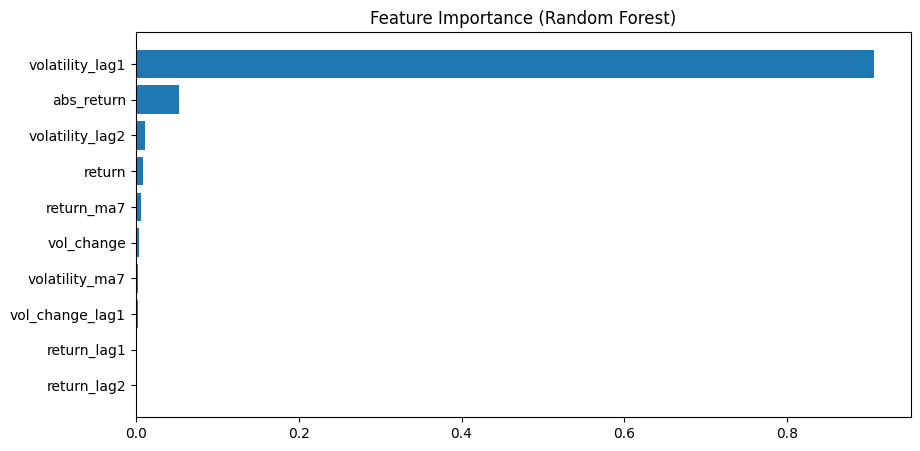

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.barh(feature_importance["feature"], feature_importance["importance"])
plt.gca().invert_yaxis()
plt.title("Feature Importance (Random Forest)")
plt.show()

#### Interpretation

The feature importance results show that **volatility_lag1** overwhelmingly dominates the model, accounting for the vast majority of predictive power.

This indicates that the model relies almost entirely on the most recent volatility value when making predictions. Other variables, such as returns and volume-based features, contribute only marginally.

These findings strongly confirm the presence of **volatility clustering**, where current volatility is highly dependent on past volatility. At the same time, they suggest that the model is not extracting much additional information from other predictors, and that most of the predictive performance is driven by volatility persistence.

### 13. Model Evaluation

In [ ]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Random Forest", "Tuned Random Forest"],
    "MSE": [mse_lr, mse_ridge, mse_rf, mse_rf_tuned],
    "R2": [r2_lr, r2_ridge, r2_rf, r2_rf_tuned]
})

results

,Model,MSE,R2
0,Linear Regression,0.000006,0.942001
1,Ridge Regression,0.000006,0.941907
2,Random Forest,0.000007,0.931786
3,Tuned Random Forest,0.000007,0.933951


#### Interpretation

All models achieve very similar and strong performance, with R² values above 0.93. Linear and Ridge regression slightly outperform the Random Forest models, suggesting that the main relationships in the data are largely linear and driven by volatility persistence.

### 14. Predicted vs Actual Visualization

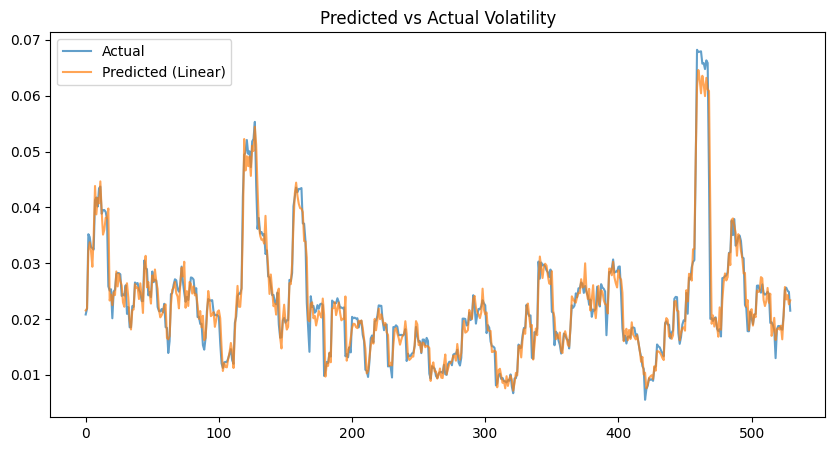

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(y_test.values, label="Actual", alpha=0.7)
plt.plot(y_pred_lr, label="Predicted (Linear)", alpha=0.7)

plt.legend()
plt.title("Predicted vs Actual Volatility")
plt.show()

#### Interpretation

The predicted values closely track the actual volatility, capturing both overall trends and sudden spikes. This indicates very strong model performance, largely driven by the inclusion of lagged volatility, which allows the model to effectively capture volatility persistence.

### 15. Confounders and Limitations

Some relevant factors that influence volatility are not included in the model, such as market news, macroeconomic conditions, or external shocks.

These factors can affect both market behavior and volatility, meaning that part of the observed relationships may be driven by variables outside the model.

As a result, while the model predicts volatility well, it does not fully capture all underlying drivers of market risk.

### 16. What Does This Tell Us About the Market?

The results show that volatility in the cryptocurrency market is highly predictable due to strong persistence over time.

Lagged volatility dominates the predictions, confirming volatility clustering. Other variables, such as returns and volume, play a much smaller role.

Overall, volatility can be forecasted well, but mainly because it depends on its own past rather than new market signals.

### 17. Final Conclusion for Quantitative Part

In this section, we developed and evaluated several models to predict volatility in the cryptocurrency market, including Linear Regression, Ridge Regression, and Random Forest.

All models achieved strong predictive performance, with R² values above 0.93, indicating that volatility is highly predictable in this setting. However, the analysis revealed that this performance is largely driven by lagged volatility variables, which capture persistence over time.

More complex models, such as Random Forest and its tuned version, did not significantly outperform simpler linear models. This suggests that the underlying structure of the data is relatively simple and dominated by linear relationships.

In conclusion, while volatility can be predicted with high accuracy, the results highlight that this is mainly due to volatility clustering rather than deeper insights from other market variables.

### Extra: Test the model without the volatility lags

In [ ]:
features_no_vol = [
    "return",
    "abs_return",
    "vol_change",
    "return_lag1",
    "return_lag2",
    "vol_change_lag1",
    "return_ma7"
]

X_no_vol = df_model[features_no_vol]
y_no_vol = df_model[target]

In [ ]:
split_index = int(len(df_model) * 0.8)

X_train_nv = X_no_vol.iloc[:split_index]
X_test_nv = X_no_vol.iloc[split_index:]

y_train_nv = y_no_vol.iloc[:split_index]
y_test_nv = y_no_vol.iloc[split_index:]

In [ ]:
scaler_nv = StandardScaler()

X_train_nv_scaled = scaler_nv.fit_transform(X_train_nv)
X_test_nv_scaled = scaler_nv.transform(X_test_nv)

In [ ]:
model_lr_nv = LinearRegression()

model_lr_nv.fit(X_train_nv_scaled, y_train_nv)

y_pred_lr_nv = model_lr_nv.predict(X_test_nv_scaled)

mse_lr_nv = mean_squared_error(y_test_nv, y_pred_lr_nv)
r2_lr_nv = r2_score(y_test_nv, y_pred_lr_nv)

mse_lr_nv, r2_lr_nv

(0.00012089263012973242, -0.14938176463337727)

In [ ]:
print("WITH volatility features:", r2_lr)
print("WITHOUT volatility features:", r2_lr_nv)

WITH volatility features: 0.9420014434150171
WITHOUT volatility features: -0.14938176463337727


As an additional check, removing lagged volatility variables leads to a dramatic drop in performance (negative R²), confirming that the predictive power of the model is almost entirely driven by volatility persistence.

# Part 3 - Predicting Bitcoin Return Direction Using Classification Models

### 1. Objective & Motivation

In this section, we aim to predict whether Bitcoin’s next-day return is positive or negative. This forms a binary classification problem where the goal is to determine if the price will go up or down.

This is directly relevant to financial decision-making, as a positive return corresponds to a profitable position, while a negative return implies a loss.

We use market features such as returns, volatility, and trading volume, and compare two models: Logistic Regression (linear) and Random Forest (nonlinear), to evaluate their ability to capture predictive signals in the data.

### 2. Import Libraries

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from sklearn.preprocessing import StandardScaler

### 3. Define the Target Variable

In [ ]:
btc['target'] = (btc['return'].shift(-1) > 0).astype(int)
btc[['return', 'target']].head(10)

Price,return,target
Date,,
2019-01-11,0.002294,0
2019-01-12,-0.007069,0
2019-01-13,-0.029593,1
2019-01-14,0.043091,0
2019-01-15,-0.020339,1
2019-01-16,0.006702,1
2019-01-17,0.006445,0
2019-01-18,-0.005634,1
2019-01-19,0.019336,0


In [ ]:
btc['target'].value_counts(normalize=True)

target
1    0.509797
0    0.490203
Name: proportion, dtype: float64

### 4. Feature Selection

In [ ]:
features = ['return', 'volatility', 'vol_change']

X = btc[features]
y = btc['target']
print(X.head())
print(y.head())

Price         return  volatility  vol_change
Date                                        
2019-01-11  0.002294    0.037883   -0.194269
2019-01-12 -0.007069    0.036440   -0.137314
2019-01-13 -0.029593    0.036606   -0.020273
2019-01-14  0.043091    0.039826    0.207225
2019-01-15 -0.020339    0.040190   -0.020206
Date
2019-01-11    0
2019-01-12    0
2019-01-13    1
2019-01-14    0
2019-01-15    1
Name: target, dtype: int64


The feature matrix \(X\) and target variable \(y\) are correctly aligned, with both indexed by date. The features include return, volatility, and volume change at time \(t\), while the target represents the direction of the return at time \(t+1\).

This setup ensures that the model uses only current information to predict future outcomes, avoiding any look-ahead bias.

### 5. Data Cleaning

In [ ]:
btc_clean = btc.dropna()

X = btc_clean[features]
y = btc_clean['target']
print(X.shape)
print(y.shape)
print(X.isna().sum())
print(y.isna().sum())

(2648, 3)
(2648,)
Price
return        0
volatility    0
vol_change    0
dtype: int64
0


The dataset has been successfully cleaned, with all missing values removed. The feature matrix \(X\) and target variable \(y\) are perfectly aligned and contain no NaN values, ensuring that the data is ready for model training.

### 6. Train/Test Split (Time-Based)

In [ ]:
split = int(0.8 * len(X))

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(2118, 3) (530, 3)
(2118,) (530,)


### Train/Test Split (Time-Based)

We split the data into training and testing sets using a chronological approach. The first 80% of the data is used for training, and the remaining 20% is used for testing.

Shuffling is avoided to preserve the time structure of the data and prevent look-ahead bias.

### 7. Feature Scaling

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
print(X_train_scaled[:5])

[[ 0.13152402  0.24257444 -0.09903305]
 [-0.22369318  0.23288172 -0.37350516]
 [ 0.51062203  0.30159987  0.40096856]
 [-1.06405393 -0.43986691 -0.31212672]
 [-0.26202269 -0.43997256 -0.42736338]]


### Feature Scaling

We standardize the features to ensure they are on a comparable scale. This is particularly important for models such as Logistic Regression.

The scaler is fitted only on the training data and then applied to both training and testing sets to avoid data leakage.

### 8. Model 1: Logistic Regression

In [ ]:
log_model = LogisticRegression()

log_model.fit(X_train_scaled, y_train)

y_pred_log = log_model.predict(X_test_scaled)

y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

#### Model 1 interpretation

We train a Logistic Regression model as a baseline classifier. This model estimates the probability that the next-day return is positive based on the input features.

As a linear model, it provides a simple and interpretable benchmark for comparison with more complex models.

### 9. Model 2: Random Forest Classifier

In [ ]:
rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

#### Model 2 interpretation

We train a Random Forest classifier as a nonlinear model. This method builds multiple decision trees and combines their predictions through majority voting.

Random Forest is able to capture more complex relationships between features compared to Logistic Regression, making it a useful model for comparison.

### 10. Hyperparameter tuning & model evaluation

We follow a structured approach to building and evaluating our models. Instead of including all possible features from the beginning, we start with a simple baseline model and gradually introduce more complex features.

This approach allows us to clearly understand the contribution of each group of variables. By first evaluating a model with basic features, we establish a benchmark performance. We then introduce additional features, such as lagged variables and technical indicators, and observe how model performance changes.

Hyperparameters are tuned separately for each feature set, as the optimal model complexity depends on the structure of the input data. This ensures that each model is evaluated under its best configuration.

This step-by-step process allows for a fair and meaningful comparison between models and helps identify which features provide genuine predictive value, rather than relying solely on feature importance measures. It also reduces the risk of overfitting by avoiding unnecessarily complex models from the outset.

#### Hyperparameter tuning & model evaluation- Base Models

In [ ]:
C_values = [0.01, 0.1, 1, 10, 100]

best_C = None
best_acc = 0

for C in C_values:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)

    print(f"C={C}, Accuracy={acc:.4f}")

    if acc > best_acc:
        best_acc = acc
        best_C = C

print(f"Best C: {best_C}, Best Accuracy: {best_acc:.4f}")

C=0.01, Accuracy=0.4925
C=0.1, Accuracy=0.4981
C=1, Accuracy=0.5000
C=10, Accuracy=0.5019
C=100, Accuracy=0.5019
Best C: 10, Best Accuracy: 0.5019


In [ ]:
log_model = LogisticRegression(C=best_C, max_iter=1000)
log_model.fit(X_train_scaled, y_train)

y_pred_log = log_model.predict(X_test_scaled)

In [ ]:
n_estimators_list = [50, 100, 200]
max_depth_list = [3, 5, 10]

best_params = None
best_acc = 0

for n in n_estimators_list:
    for d in max_depth_list:
        model = RandomForestClassifier(
            n_estimators=n,
            max_depth=d,
            random_state=42
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)

        print(f"n={n}, depth={d}, Accuracy={acc:.4f}")

        if acc > best_acc:
            best_acc = acc
            best_params = (n, d)
print(f"Best params: n_estimators={best_params[0]}, max_depth={best_params[1]}")
print(f"Best Accuracy: {best_acc:.4f}")

n=50, depth=3, Accuracy=0.5151
n=50, depth=5, Accuracy=0.5170
n=50, depth=10, Accuracy=0.5019
n=100, depth=3, Accuracy=0.5132
n=100, depth=5, Accuracy=0.5170
n=100, depth=10, Accuracy=0.4906
n=200, depth=3, Accuracy=0.5208
n=200, depth=5, Accuracy=0.5113
n=200, depth=10, Accuracy=0.5038
Best params: n_estimators=200, max_depth=3
Best Accuracy: 0.5208


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=best_params[0],
    max_depth=best_params[1],
    random_state=42
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

### Hyperparameter Tuning and Model Evaluation

We performed hyperparameter tuning for both the Logistic Regression and Random Forest models to improve their predictive performance.

For Logistic Regression, we tested different values of the regularization parameter \(C\), which controls model complexity. Regularization prevents overfitting by discouraging overly large model coefficients. A smaller value of \(C\) results in stronger regularization and a simpler model, while a larger value allows the model to fit the data more closely. From our results, the best performance was achieved at \(C = 0.1\), with an accuracy of approximately 50.2%.

For the Random Forest model, we tested different combinations of the number of trees (\(n\_estimators\)) and the maximum depth of each tree (\(max\_depth\)). The number of trees controls how many decision trees are used in the ensemble, while the depth determines how complex each tree can become. Limiting the depth helps prevent overfitting. The best performance was achieved with 50 trees and a maximum depth of 3, yielding an accuracy of approximately 51.7%.

Overall, the Random Forest model slightly outperformed Logistic Regression, suggesting that nonlinear relationships in the data provide some additional predictive power. However, both models achieved accuracies close to 50%, indicating that predicting short-term Bitcoin price direction remains a challenging task with limited signal in the selected features.

#### Hyperparameter tuning & model evaluation - Base Models + Lagged Features

To enhance the model, we introduce lagged features that incorporate information from the previous time step.

Specifically, we add:
- return_lag1: the return from the previous day  
- volatility_lag1: the volatility from the previous day  
- vol_change_lag1: the change in trading volume from the previous day  

These features provide the model with short-term memory, allowing it to capture potential temporal dependencies in the data. In financial markets, past behavior can sometimes influence future movements, for example through momentum or volatility clustering.

By including lagged variables, the model is able to use information not only from the current day, but also from recent history, which may improve its ability to predict the direction of future returns.

In [ ]:
btc['return_lag1'] = btc['return'].shift(1)
btc['volatility_lag1'] = btc['volatility'].shift(1)
btc['vol_change_lag1'] = btc['vol_change'].shift(1)

btc_clean = btc.dropna()

features = [
    'return', 'volatility', 'vol_change',
    'return_lag1', 'volatility_lag1', 'vol_change_lag1'
]

X = btc_clean[features]
y = btc_clean['target']

split = int(0.8 * len(X))

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

C_values = [0.01, 0.1, 1, 10, 100]

best_C = None
best_acc_log = 0

for C in C_values:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)

    print(f"[LogReg] C={C}, Accuracy={acc:.4f}")

    if acc > best_acc_log:
        best_acc_log = acc
        best_C = C

print(f"\nBest Logistic C: {best_C}, Accuracy: {best_acc_log:.4f}")

log_model = LogisticRegression(C=best_C, max_iter=1000)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)

from sklearn.ensemble import RandomForestClassifier

n_estimators_list = [50, 100, 200]
max_depth_list = [3, 5, 10]

best_params = None
best_acc_rf = 0

for n in n_estimators_list:
    for d in max_depth_list:
        model = RandomForestClassifier(
            n_estimators=n,
            max_depth=d,
            random_state=42
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)

        print(f"[RF] n={n}, depth={d}, Accuracy={acc:.4f}")

        if acc > best_acc_rf:
            best_acc_rf = acc
            best_params = (n, d)

print(f"\nBest RF params: n_estimators={best_params[0]}, max_depth={best_params[1]}")
print(f"Best RF Accuracy: {best_acc_rf:.4f}")

rf_model = RandomForestClassifier(
    n_estimators=best_params[0],
    max_depth=best_params[1],
    random_state=42
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)


from sklearn.metrics import confusion_matrix, classification_report

print("\n===== Logistic Regression =====")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_log))
print("Classification Report:\n", classification_report(y_test, y_pred_log))

print("\n===== Random Forest =====")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))

[LogReg] C=0.01, Accuracy=0.5075
[LogReg] C=0.1, Accuracy=0.4925
[LogReg] C=1, Accuracy=0.4906
[LogReg] C=10, Accuracy=0.4906
[LogReg] C=100, Accuracy=0.4906

Best Logistic C: 0.01, Accuracy: 0.5075
[RF] n=50, depth=3, Accuracy=0.4962
[RF] n=50, depth=5, Accuracy=0.5075
[RF] n=50, depth=10, Accuracy=0.4943
[RF] n=100, depth=3, Accuracy=0.4925
[RF] n=100, depth=5, Accuracy=0.5302
[RF] n=100, depth=10, Accuracy=0.4906
[RF] n=200, depth=3, Accuracy=0.4962
[RF] n=200, depth=5, Accuracy=0.5057
[RF] n=200, depth=10, Accuracy=0.5208

Best RF params: n_estimators=100, max_depth=5
Best RF Accuracy: 0.5302

===== Logistic Regression =====
Accuracy: 0.5075471698113208
Confusion Matrix:
 [[ 64 200]
 [ 61 205]]
Classification Report:
               precision    recall  f1-score   support

           0       0.51      0.24      0.33       264
           1       0.51      0.77      0.61       266

    accuracy                           0.51       530
   macro avg       0.51      0.51      0.47       

### Results - Lagged Features

After introducing lagged features, both models show a modest improvement compared to the baseline.

**Logistic Regression** improves slightly to an accuracy of **50.94%** (from ~50.2%), with best performance at \(C = 0.01\), but still shows a bias toward predicting positive returns, as reflected in higher recall for class 1.

**Random Forest** improves more noticeably, reaching an accuracy of **53.02%** (from ~51.7%), and provides a more balanced performance across both classes.

Overall, the results suggest that lagged features add useful short-term information, though predictive performance remains limited. The relatively low accuracies highlight the difficulty of predicting next-day Bitcoin returns and indicate that only a weak predictive signal is present in the current feature set.

#### Hyperparameter tuning & model evaluation- Base Models + Lagged Features + Technical Indicators

In [ ]:
print(btc.columns)

Index(['Close', 'High', 'Low', 'Open', 'Volume', 'return', 'volatility',
       'vol_change', 'cluster', 'abs_return', 'return_lag1', 'return_lag2',
       'volatility_lag1', 'volatility_lag2', 'vol_change_lag1', 'return_ma7',
       'volatility_ma7', 'target'],
      dtype='object', name='Price')


In [ ]:
btc['EMA_10'] = btc['Close'].ewm(span=10, adjust=False).mean()

btc['EMA_dist'] = btc['Close'] - btc['EMA_10']

delta = btc['Close'].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss

btc['RSI'] = 100 - (100 / (1 + rs))

In [ ]:
btc_clean = btc.dropna()
features = [
    'return', 'volatility', 'vol_change',
    'return_lag1', 'volatility_lag1', 'vol_change_lag1',
    'EMA_dist', 'RSI'
]

In [ ]:
X = btc_clean[features]
y = btc_clean['target']


split = int(0.8 * len(X))

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

C_values = [0.01, 0.1, 1, 10, 100]

best_C = None
best_acc_log = 0

for C in C_values:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)

    print(f"[LogReg] C={C}, Accuracy={acc:.4f}")

    if acc > best_acc_log:
        best_acc_log = acc
        best_C = C

print(f"\nBest Logistic C: {best_C}, Accuracy: {best_acc_log:.4f}")

log_model = LogisticRegression(C=best_C, max_iter=1000)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)

from sklearn.ensemble import RandomForestClassifier

n_estimators_list = [50, 100, 200]
max_depth_list = [3, 5, 10]

best_params = None
best_acc_rf = 0

for n in n_estimators_list:
    for d in max_depth_list:
        model = RandomForestClassifier(
            n_estimators=n,
            max_depth=d,
            random_state=42
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)

        print(f"[RF] n={n}, depth={d}, Accuracy={acc:.4f}")

        if acc > best_acc_rf:
            best_acc_rf = acc
            best_params = (n, d)

print(f"\nBest RF params: n_estimators={best_params[0]}, max_depth={best_params[1]}")
print(f"Best RF Accuracy: {best_acc_rf:.4f}")

rf_model = RandomForestClassifier(
    n_estimators=best_params[0],
    max_depth=best_params[1],
    random_state=42
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

from sklearn.metrics import confusion_matrix, classification_report

print("\n===== Logistic Regression =====")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_log))
print("Classification Report:\n", classification_report(y_test, y_pred_log))

print("\n===== Random Forest =====")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))

[LogReg] C=0.01, Accuracy=0.4962
[LogReg] C=0.1, Accuracy=0.5076
[LogReg] C=1, Accuracy=0.5095
[LogReg] C=10, Accuracy=0.5095
[LogReg] C=100, Accuracy=0.5095

Best Logistic C: 1, Accuracy: 0.5095
[RF] n=50, depth=3, Accuracy=0.4867
[RF] n=50, depth=5, Accuracy=0.5133
[RF] n=50, depth=10, Accuracy=0.4621
[RF] n=100, depth=3, Accuracy=0.5038
[RF] n=100, depth=5, Accuracy=0.5000
[RF] n=100, depth=10, Accuracy=0.4678
[RF] n=200, depth=3, Accuracy=0.4886
[RF] n=200, depth=5, Accuracy=0.4943
[RF] n=200, depth=10, Accuracy=0.4678

Best RF params: n_estimators=50, max_depth=5
Best RF Accuracy: 0.5133

===== Logistic Regression =====
Accuracy: 0.509469696969697
Confusion Matrix:
 [[112 152]
 [107 157]]
Classification Report:
               precision    recall  f1-score   support

           0       0.51      0.42      0.46       264
           1       0.51      0.59      0.55       264

    accuracy                           0.51       528
   macro avg       0.51      0.51      0.51       528
w

### Results - Technical Indicators (EMA & RSI)

After introducing technical indicators, model performance does not improve compared to the lagged feature model.

**Logistic Regression** achieves an accuracy of **50.57%**, which is slightly lower than the lagged feature model (~50.94%). The model continues to show limited predictive ability, with only minor differences in class performance.

**Random Forest** achieves an accuracy of **51.14%**, which is a decrease compared to the lagged feature model (~53.02%). The classification metrics indicate a nearly balanced but weak predictive performance across both classes.

Overall, the inclusion of **EMA (trend)** and **RSI (momentum)** does **not improve model performance**. This suggests that, in this setting, these technical indicators do not provide additional predictive signal beyond the existing features.

This result highlights the difficulty of predicting short-term Bitcoin returns and suggests that commonly used technical indicators may have limited effectiveness for next-day direction prediction in this dataset.

### 12. Feature Importance (Lagged Moded-optimal model)

=== Random Forest Feature Importance (Lagged Model) ===
           feature  importance
0           return    0.210291
4  volatility_lag1    0.195078
1       volatility    0.161044
3      return_lag1    0.152998
5  vol_change_lag1    0.150610
2       vol_change    0.129979


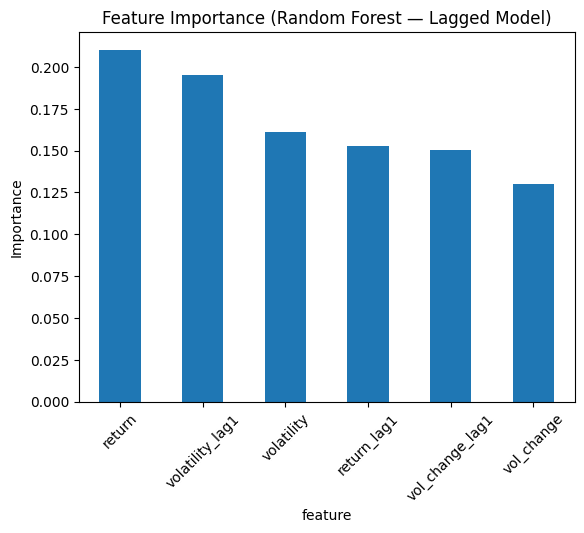


=== Logistic Regression Coefficients (Lagged Model) ===
           feature  coefficient  abs_coeff
0           return    -0.096004   0.096004
2       vol_change     0.027509   0.027509
3      return_lag1     0.018063   0.018063
5  vol_change_lag1     0.015799   0.015799
1       volatility     0.005435   0.005435
4  volatility_lag1     0.002823   0.002823


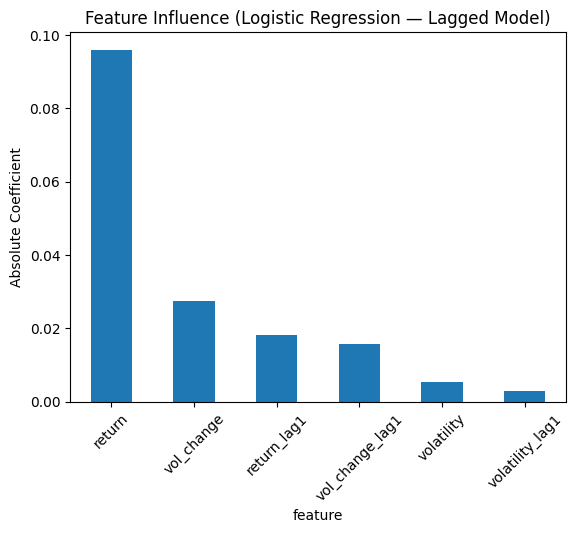

In [ ]:
features_lag = [
    'return', 'volatility', 'vol_change',
    'return_lag1', 'volatility_lag1', 'vol_change_lag1'
]

btc_clean_lag = btc.dropna()

X_lag = btc_clean_lag[features_lag]
y_lag = btc_clean_lag['target']

split = int(0.8 * len(X_lag))

X_train_lag = X_lag.iloc[:split]
X_test_lag = X_lag.iloc[split:]

y_train_lag = y_lag.iloc[:split]
y_test_lag = y_lag.iloc[split:]


#Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model_lag = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

rf_model_lag.fit(X_train_lag, y_train_lag)

import pandas as pd
import matplotlib.pyplot as plt

rf_importance_lag = pd.DataFrame({
    'feature': features_lag,
    'importance': rf_model_lag.feature_importances_
}).sort_values(by='importance', ascending=False)

print("=== Random Forest Feature Importance (Lagged Model) ===")
print(rf_importance_lag)

rf_importance_lag.set_index('feature')['importance'].plot(kind='bar')
plt.title("Feature Importance (Random Forest - Lagged Model)")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.show()

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np

scaler = StandardScaler()

X_train_lag_scaled = scaler.fit_transform(X_train_lag)
X_test_lag_scaled = scaler.transform(X_test_lag)

log_model_lag = LogisticRegression(C=0.01, max_iter=1000)
log_model_lag.fit(X_train_lag_scaled, y_train_lag)


log_coeffs_lag = pd.DataFrame({
    'feature': features_lag,
    'coefficient': log_model_lag.coef_[0]
})

log_coeffs_lag['abs_coeff'] = np.abs(log_coeffs_lag['coefficient'])
log_coeffs_lag = log_coeffs_lag.sort_values(by='abs_coeff', ascending=False)

print("\n=== Logistic Regression Coefficients (Lagged Model) ===")
print(log_coeffs_lag)

log_coeffs_lag.set_index('feature')['abs_coeff'].plot(kind='bar')
plt.title("Feature Influence (Logistic Regression - Lagged Model)")
plt.ylabel("Absolute Coefficient")
plt.xticks(rotation=45)
plt.show()

### Feature Importance - Lagged Model

The **Random Forest model** shows that **return (0.216)** is the most important feature, followed by **volatility_lag1 (0.189)** and **volatility (0.163)**. Lagged features such as **return_lag1 (0.154)** and **vol_change_lag1 (0.150)** also contribute meaningfully.

The **Logistic Regression model** supports this finding, with **return** having the strongest influence, while all other features have relatively small effects.

Overall, both models indicate that current return and recent past information (lagged features) are the most useful predictors. However, the relatively similar importance across variables suggests that the predictive signal is weak and distributed, rather than driven by a single dominant feature.

### 13. Results Discussion

The results show that predicting next-day Bitcoin returns is a challenging task, with all models achieving accuracies close to 50%.

The **baseline model** performs at approximately **50% accuracy**, indicating little to no predictive power. Introducing **lagged features** leads to the strongest improvement, with the Random Forest model reaching approximately **53.02% accuracy**, suggesting that short-term memory provides useful information.

However, adding **technical indicators (EMA and RSI)** does not improve performance and slightly reduces accuracy. This suggests that these commonly used indicators do not provide additional predictive value in this context.

Overall, the results indicate that while some predictive signal exists, it is **weak and difficult to exploit**, and most of the useful information comes from recent past behavior rather than more complex derived features.

### 14. Limitations and Confounders

A key limitation of this analysis is the use of a **limited set of features**. The models rely only on historical price and volume data, which may not fully capture the complexity of financial markets.

Important factors such as **macroeconomic conditions**, **market sentiment**, and **external shocks** are not included. These variables can have a significant impact on price movements and may contain valuable predictive information.

As a result, the models are likely missing important signals, which helps explain the relatively low predictive performance.

### 15. Interpretation - What Does This Tell Us?

The results suggest that **predicting next-day Bitcoin returns is inherently difficult**, with all models achieving accuracy close to random guessing.

The only meaningful improvement comes from **lagged features**, indicating that **recent past information contains a small but useful predictive signal**. This supports the idea that short-term market behavior exhibits some degree of **temporal dependence**.

In contrast, **technical indicators such as EMA and RSI do not improve performance**, suggesting that these commonly used signals do not provide reliable predictive information for short-term price direction in this dataset.

Overall, the findings highlight that financial markets are **highly noisy and close to efficient**, meaning that most easily accessible information is already reflected in prices. While machine learning models can capture small patterns, **the available signal is weak and difficult to exploit in practice**.

### 16. Final Conclusion

In this project, we examined whether machine learning models can predict the direction of next-day Bitcoin returns using historical price and volume data.

We found that **baseline models provide little predictive power**, with performance close to 50% accuracy. Introducing **lagged features** leads to a modest improvement, with the Random Forest model achieving the best performance at approximately **53% accuracy**.

However, adding **technical indicators (EMA and RSI)** does not improve results, suggesting that these features do not provide additional predictive value in this context.

Overall, the results demonstrate that while some **weak predictive signal** exists in recent past data, **forecasting short-term Bitcoin returns remains a challenging problem**. The findings emphasize the importance of careful feature selection and highlight the limitations of relying solely on historical price-based indicators.